# OREX / NEO-REX Rescaling Sandbox

Notebook volutamente senza fit. L'idea e': caricare tutti i dati disponibili, costruire colonne geometriche esplicite, guardare i plot raw/rescaled, e in fondo cambiare una sola funzione `custom_x(df)` per testare ansatz diversi.

In [1]:

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from scipy.special import erfcinv
except Exception:
    erfcinv = None

OUT_DIR = Path('.') if Path('recovered_orex_metrics.csv').exists() else Path('plot/orex_recovered_from_txt')
FIG_DIR = OUT_DIR / 'rescaling_sandbox_figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 180,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'font.size': 10,
})


## Load and Standardize Data

In [2]:

INPUT_FILES = [
    OUT_DIR / 'recovered_orex_metrics.csv',
    OUT_DIR / 'recovered_neorex_eval_metrics.csv',
    OUT_DIR / 'recovered_orex_d3_metrics.csv',
]

def infer_defect_size(row):
    if 'defect_size' in row and pd.notna(row['defect_size']):
        return int(row['defect_size'])
    text = ' '.join(str(row.get(k, '')) for k in ['study_name', 'run_name', 'output_dir', 'wandb_run_name'])
    match = re.search(r'[_-]d(\d+)', text)
    if match:
        return int(match.group(1))
    return 2

def clean_algorithm(value):
    value = str(value).strip().lower()
    if value == 'neorex':
        return 'NEO-REX pretrained'
    if value == 'orex':
        return 'OREX'
    return value

frames = []
for path in INPUT_FILES:
    if not path.exists():
        print(f'Missing: {path}')
        continue
    frame = pd.read_csv(path)
    frame['source_file'] = path.name
    frames.append(frame)

raw = pd.concat(frames, ignore_index=True, sort=False)
raw['algorithm'] = raw['algorithm'].map(clean_algorithm)
raw['nreplicas'] = pd.to_numeric(raw['nreplicas'], errors='coerce').astype('Int64')
raw['nsteps'] = pd.to_numeric(raw['nsteps'], errors='coerce').astype('Int64')
raw['swap_acceptance'] = pd.to_numeric(raw['swap_acceptance'], errors='coerce')
raw['work_mean'] = pd.to_numeric(raw['work_mean'], errors='coerce')
raw['work_sem'] = pd.to_numeric(raw['work_sem'], errors='coerce')
raw['total_accepted'] = pd.to_numeric(raw.get('total_accepted'), errors='coerce')
raw['total_proposed'] = pd.to_numeric(raw.get('total_proposed'), errors='coerce')
raw['defect_size'] = raw.apply(infer_defect_size, axis=1).astype(int)
raw['defect_volume'] = raw['defect_size'] ** 3
raw['nsteps_raw'] = raw['nsteps'].astype(float)
raw['nsteps_plus1'] = raw['nsteps_raw'] + 1.0
raw['nsteps_eff'] = raw['nsteps_raw']
raw['nreplicas_f'] = raw['nreplicas'].astype(float)
raw['nr_minus_1'] = raw['nreplicas_f'] - 1.0
raw['n_defect_links'] = raw['defect_volume']
raw['n_defect_plaquettes'] = 3.0 * raw['defect_size'] ** 2 * (raw['defect_size'] + 1.0)
raw['swap_acceptance_sem'] = np.sqrt(raw['swap_acceptance'] * (1.0 - raw['swap_acceptance']) / raw['total_proposed'])
if erfcinv is not None:
    raw['erfcinv_acceptance'] = erfcinv(np.clip(raw['swap_acceptance'], 1e-12, 1.0 - 1e-12))

raw = raw.sort_values(['algorithm', 'defect_size', 'nreplicas', 'nsteps']).reset_index(drop=True)
raw[['algorithm', 'defect_size', 'defect_volume', 'n_defect_plaquettes', 'nreplicas', 'nsteps', 'nsteps_raw', 'nsteps_plus1', 'nsteps_eff', 'swap_acceptance', 'swap_acceptance_sem', 'work_mean', 'work_sem', 'source_file']]


,algorithm,defect_size,defect_volume,n_defect_plaquettes,nreplicas,nsteps,nsteps_raw,nsteps_plus1,nsteps_eff,swap_acceptance,swap_acceptance_sem,work_mean,work_sem,source_file
0,NEO-REX pretrained,2,8,36.0,4,2,2.0,3.0,2.0,0.078464,0.001372,6.952978,0.021290,recovered_neorex_eval_metrics.csv
1,NEO-REX pretrained,2,8,36.0,4,4,4.0,5.0,4.0,0.199271,0.002038,3.530432,0.014540,recovered_neorex_eval_metrics.csv
2,NEO-REX pretrained,2,8,36.0,4,6,6.0,7.0,6.0,0.289141,0.002314,2.367685,0.011760,recovered_neorex_eval_metrics.csv
3,NEO-REX pretrained,2,8,36.0,4,8,8.0,9.0,8.0,0.353490,0.002440,1.789984,0.010170,recovered_neorex_eval_metrics.csv
4,NEO-REX pretrained,2,8,36.0,8,2,2.0,3.0,2.0,0.457455,0.001664,1.172992,0.005558,recovered_neorex_eval_metrics.csv
5,NEO-REX pretrained,2,8,36.0,8,4,4.0,5.0,4.0,0.583281,0.001647,0.619129,0.003950,recovered_neorex_eval_metrics.csv
6,NEO-REX pretrained,2,8,36.0,8,6,6.0,7.0,6.0,0.648393,0.001595,0.428084,0.003240,recovered_neorex_eval_metrics.csv
7,NEO-REX pretrained,2,8,36.0,8,8,8.0,9.0,8.0,0.690379,0.001545,0.322369,0.002788,recovered_neorex_eval_metrics.csv
8,OREX,2,8,36.0,4,0,0.0,1.0,0.0,0.010286,0.000515,15.468660,0.035250,recovered_orex_metrics.csv
9,OREX,2,8,36.0,4,2,2.0,3.0,2.0,0.058750,0.001200,7.980036,0.023260,recovered_orex_metrics.csv


## Standard Rescaled Columns

In [3]:

data = raw.copy()
N = data['nreplicas_f']
Nm1 = data['nr_minus_1']
neff = data['nsteps_eff']
Vdef = data['defect_volume'].astype(float)
Nplaq = data['n_defect_plaquettes'].astype(float)

# Basic candidates. nsteps_eff is the raw protocol step count, so nsteps=0 stays exactly 0.
data['x_vdef_Nm1sq'] = neff * Nm1**2 / Vdef
data['x_vdef_Nrsq'] = neff * N**2 / Vdef
data['x_vdef_Nr'] = neff * N / Vdef
data['x_vdef_Nm1'] = neff * Nm1 / Vdef

data['x_plaq_Nm1sq'] = neff * Nm1**2 / Nplaq
data['x_plaq_Nrsq'] = neff * N**2 / Nplaq
data['x_plaq_Nr'] = neff * N / Nplaq

data['z_sqrt_vdef_Nm1'] = np.sqrt(neff) * Nm1 / np.sqrt(Vdef)
data['z_sqrt_vdef_Nr'] = np.sqrt(neff) * N / np.sqrt(Vdef)
data['z_sqrt_plaq_Nm1'] = np.sqrt(neff) * Nm1 / np.sqrt(Nplaq)
data['z_sqrt_plaq_Nr'] = np.sqrt(neff) * N / np.sqrt(Nplaq)

# Useful inverse variables for erfc^{-1}(acceptance) diagnostics.
for col in ['z_sqrt_vdef_Nm1', 'z_sqrt_vdef_Nr', 'z_sqrt_plaq_Nm1', 'z_sqrt_plaq_Nr']:
    data[f'inv_{col}'] = 1.0 / data[col]

rescaled_cols = [c for c in data.columns if c.startswith('x_') or c.startswith('z_') or c.startswith('inv_z_')]
data[['algorithm', 'defect_size', 'nreplicas', 'nsteps', 'swap_acceptance', 'work_mean'] + rescaled_cols]


,algorithm,defect_size,nreplicas,nsteps,swap_acceptance,work_mean,x_vdef_Nm1sq,x_vdef_Nrsq,x_vdef_Nr,x_vdef_Nm1,...,x_plaq_Nrsq,x_plaq_Nr,z_sqrt_vdef_Nm1,z_sqrt_vdef_Nr,z_sqrt_plaq_Nm1,z_sqrt_plaq_Nr,inv_z_sqrt_vdef_Nm1,inv_z_sqrt_vdef_Nr,inv_z_sqrt_plaq_Nm1,inv_z_sqrt_plaq_Nr
0,NEO-REX pretrained,2,4,2,0.078464,6.952978,2.250000,4.000000,1.000000,0.750000,...,0.888889,0.222222,1.500000,2.000000,0.707107,0.942809,0.666667,0.500000,1.414214,1.060660
1,NEO-REX pretrained,2,4,4,0.199271,3.530432,4.500000,8.000000,2.000000,1.500000,...,1.777778,0.444444,2.121320,2.828427,1.000000,1.333333,0.471405,0.353553,1.000000,0.750000
2,NEO-REX pretrained,2,4,6,0.289141,2.367685,6.750000,12.000000,3.000000,2.250000,...,2.666667,0.666667,2.598076,3.464102,1.224745,1.632993,0.384900,0.288675,0.816497,0.612372
3,NEO-REX pretrained,2,4,8,0.353490,1.789984,9.000000,16.000000,4.000000,3.000000,...,3.555556,0.888889,3.000000,4.000000,1.414214,1.885618,0.333333,0.250000,0.707107,0.530330
4,NEO-REX pretrained,2,8,2,0.457455,1.172992,12.250000,16.000000,2.000000,1.750000,...,3.555556,0.444444,3.500000,4.000000,1.649916,1.885618,0.285714,0.250000,0.606092,0.530330
5,NEO-REX pretrained,2,8,4,0.583281,0.619129,24.500000,32.000000,4.000000,3.500000,...,7.111111,0.888889,4.949747,5.656854,2.333333,2.666667,0.202031,0.176777,0.428571,0.375000
6,NEO-REX pretrained,2,8,6,0.648393,0.428084,36.750000,48.000000,6.000000,5.250000,...,10.666667,1.333333,6.062178,6.928203,2.857738,3.265986,0.164957,0.144338,0.349927,0.306186
7,NEO-REX pretrained,2,8,8,0.690379,0.322369,49.000000,64.000000,8.000000,7.000000,...,14.222222,1.777778,7.000000,8.000000,3.299832,3.771236,0.142857,0.125000,0.303046,0.265165
8,OREX,2,4,0,0.010286,15.468660,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,inf,inf,inf,inf
9,OREX,2,4,2,0.058750,7.980036,2.250000,4.000000,1.000000,0.750000,...,0.888889,0.222222,1.500000,2.000000,0.707107,0.942809,0.666667,0.500000,1.414214,1.060660


In [4]:

# Save the full table so the same data can be reused outside the notebook.
out_csv = OUT_DIR / 'rescaling_sandbox_data.csv'
data.to_csv(out_csv, index=False)
out_csv


PosixPath('rescaling_sandbox_data.csv')

## Plot Helpers

In [5]:

algorithm_markers = {
    'OREX': 'o',
    'NEO-REX pretrained': 's',
}
replica_colors = {
    4: 'tab:blue',
    8: 'tab:orange',
}

def point_style(algorithm, nreplicas, defect_volume):
    color = replica_colors.get(int(nreplicas), None)
    filled = int(defect_volume) == 8
    return {
        'marker': algorithm_markers.get(algorithm, 'o'),
        'color': color,
        'markerfacecolor': color if filled else 'none',
        'markeredgewidth': 1.0 if filled else 1.8,
    }

def grouped(frame):
    cols = ['algorithm', 'nreplicas', 'defect_volume']
    for (algorithm, nrep, vdef), sub in frame.groupby(cols, sort=True):
        yield algorithm, int(nrep), int(vdef), sub.sort_values(['nsteps', 'defect_size'])

def plot_metric_vs(frame, x_col, y_col, *, yerr_col=None, logx=False, logy=False, title=None, save_name=None):
    fig, ax = plt.subplots(figsize=(7.0, 4.2))
    for algorithm, nrep, vdef, sub in grouped(frame):
        style = point_style(algorithm, nrep, vdef)
        yerr = sub[yerr_col] if yerr_col and yerr_col in sub.columns else None
        ax.errorbar(
            sub[x_col],
            sub[y_col],
            yerr=yerr,
            linestyle='None',
            capsize=3,
            label=fr'{algorithm}, $N_r={nrep}$, $V_{{\mathrm{{def}}}}={vdef}$',
            **style,
        )
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    if logx:
        ax.set_xscale('log')
    if logy:
        ax.set_yscale('log')
    if title:
        ax.set_title(title)
    ax.legend(frameon=False, fontsize=7)
    fig.tight_layout()
    if save_name:
        fig.savefig(FIG_DIR / f'{save_name}.png', bbox_inches='tight')
        fig.savefig(FIG_DIR / f'{save_name}.pdf', bbox_inches='tight')
    return fig, ax


## Raw Data Plots

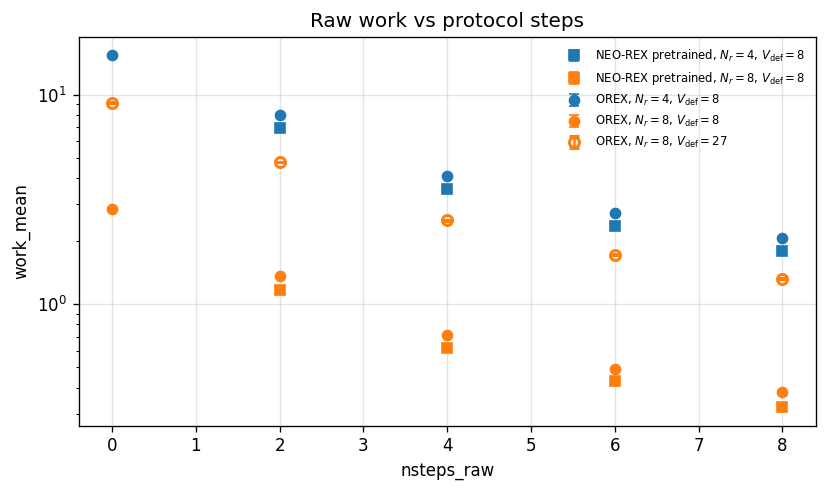

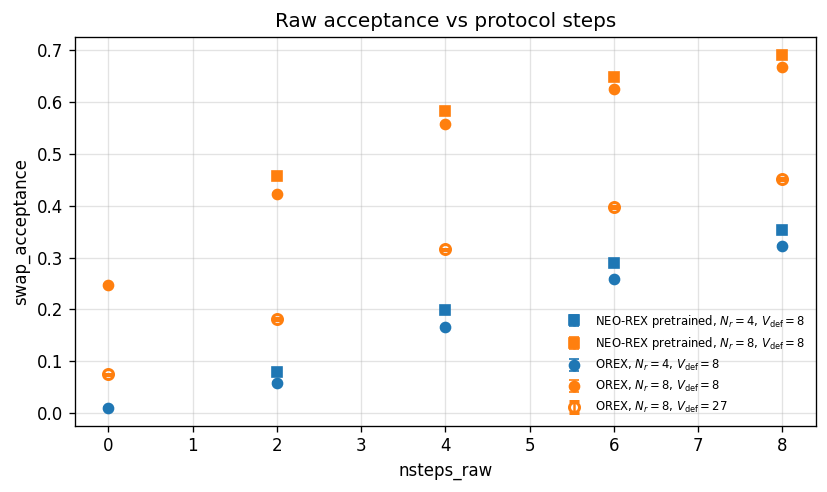

In [6]:

plot_metric_vs(data, 'nsteps_raw', 'work_mean', yerr_col='work_sem', logx=False, logy=True, title='Raw work vs protocol steps', save_name='raw_work_vs_nsteps_raw')
plt.show()

plot_metric_vs(data, 'nsteps_raw', 'swap_acceptance', yerr_col='swap_acceptance_sem', logx=False, logy=False, title='Raw acceptance vs protocol steps', save_name='raw_acceptance_vs_nsteps_raw')
plt.show()


## Quick Rescaling Comparisons

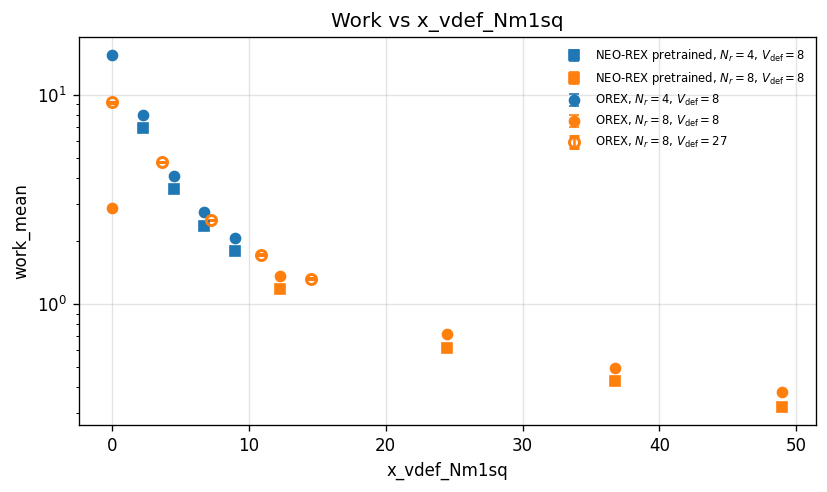

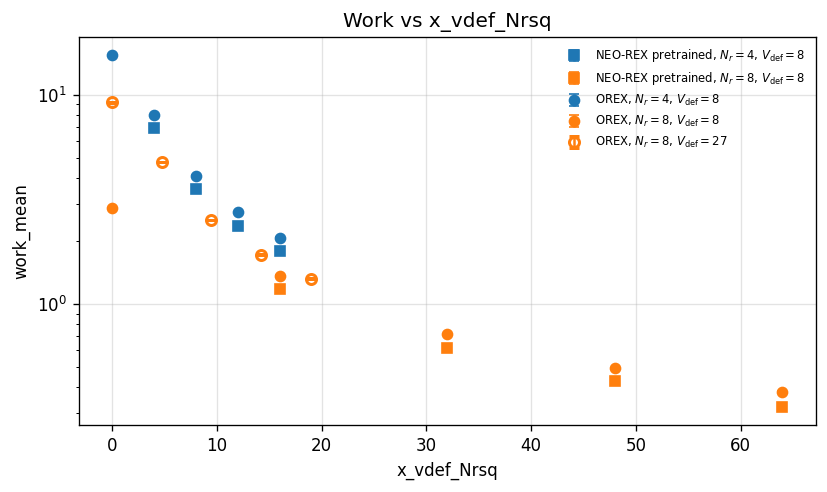

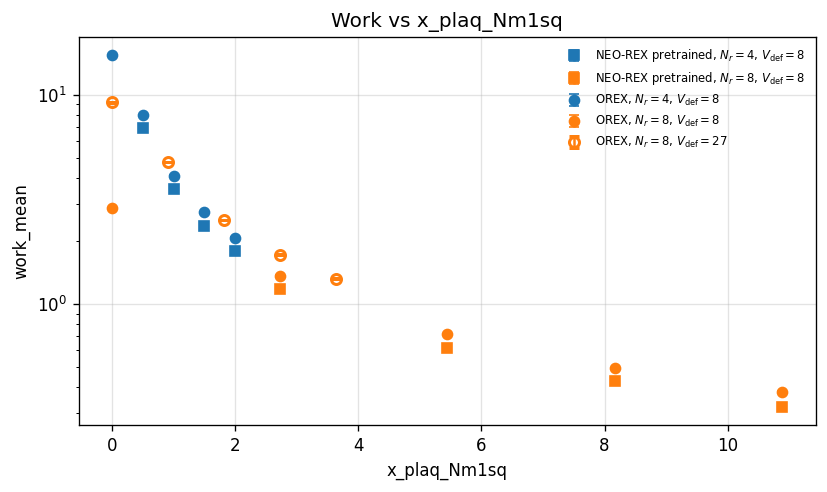

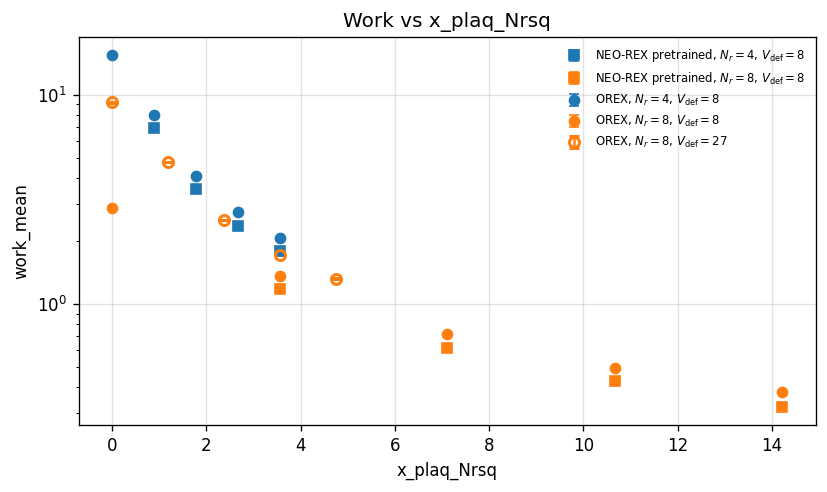

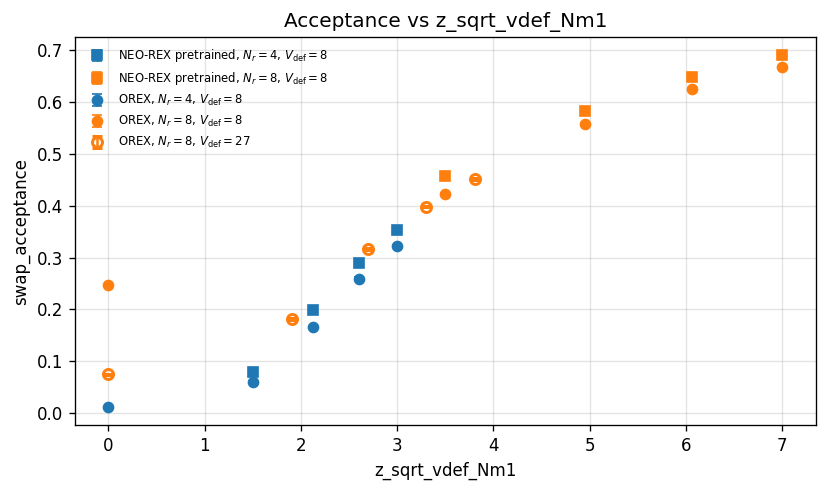

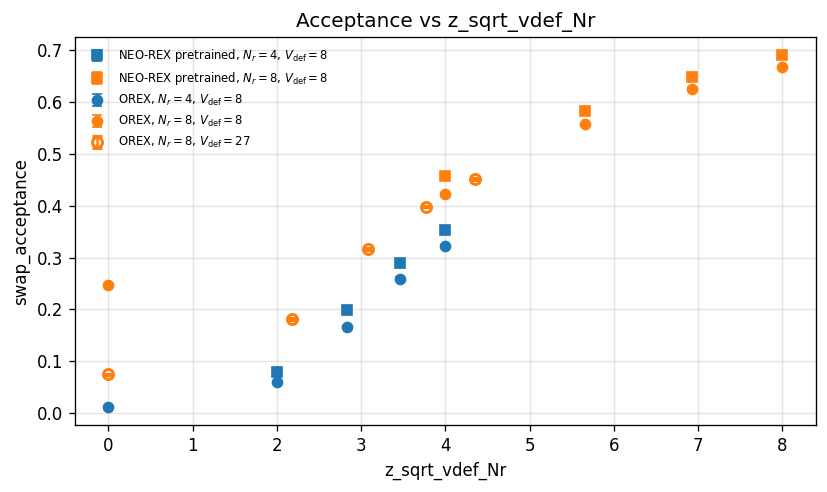

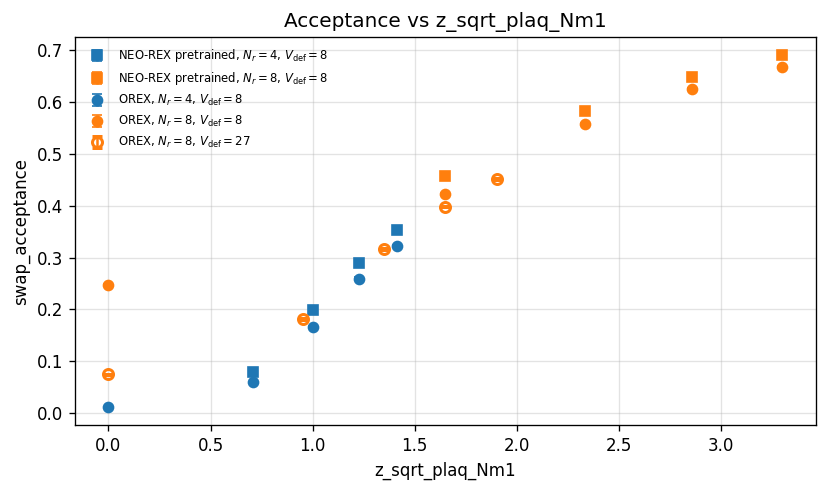

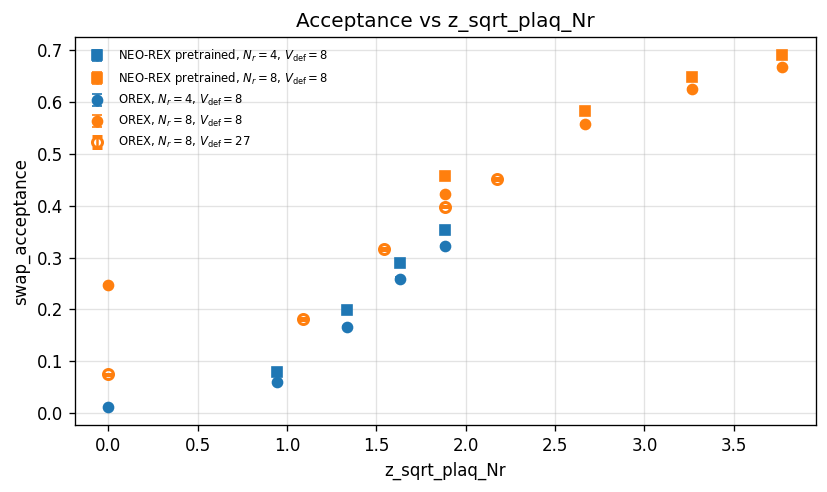

In [7]:

# Change these lists if you want fewer/more panels.
work_x_columns = [
    'x_vdef_Nm1sq',
    'x_vdef_Nrsq',
    'x_plaq_Nm1sq',
    'x_plaq_Nrsq',
]
acceptance_x_columns = [
    'z_sqrt_vdef_Nm1',
    'z_sqrt_vdef_Nr',
    'z_sqrt_plaq_Nm1',
    'z_sqrt_plaq_Nr',
]

for x_col in work_x_columns:
    plot_metric_vs(data, x_col, 'work_mean', yerr_col='work_sem', logx=False, logy=True, title=f'Work vs {x_col}', save_name=f'work_vs_{x_col}')
    plt.show()

for x_col in acceptance_x_columns:
    plot_metric_vs(data, x_col, 'swap_acceptance', yerr_col='swap_acceptance_sem', logx=False, logy=False, title=f'Acceptance vs {x_col}', save_name=f'acceptance_vs_{x_col}')
    plt.show()


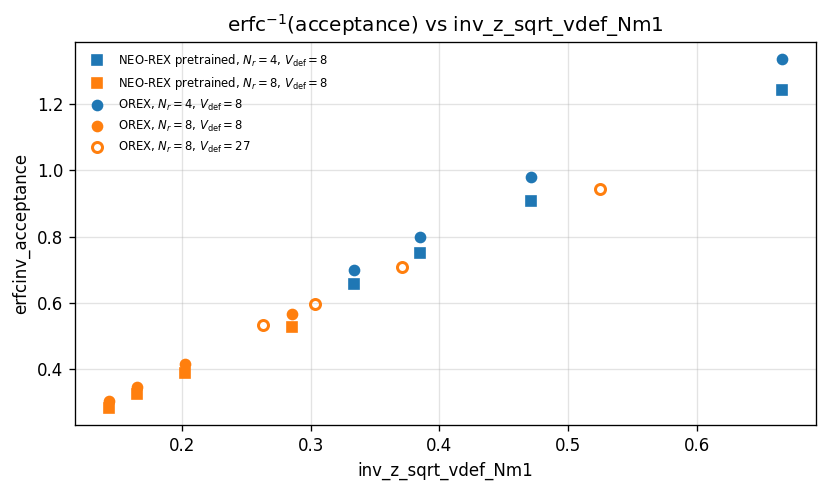

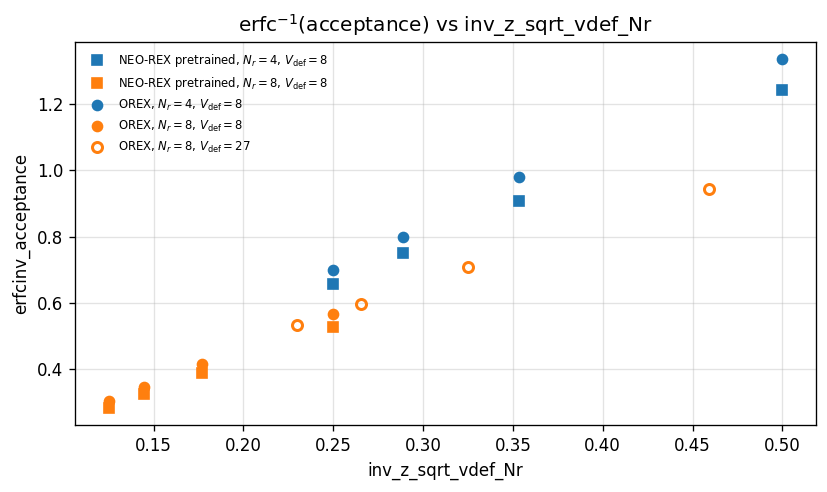

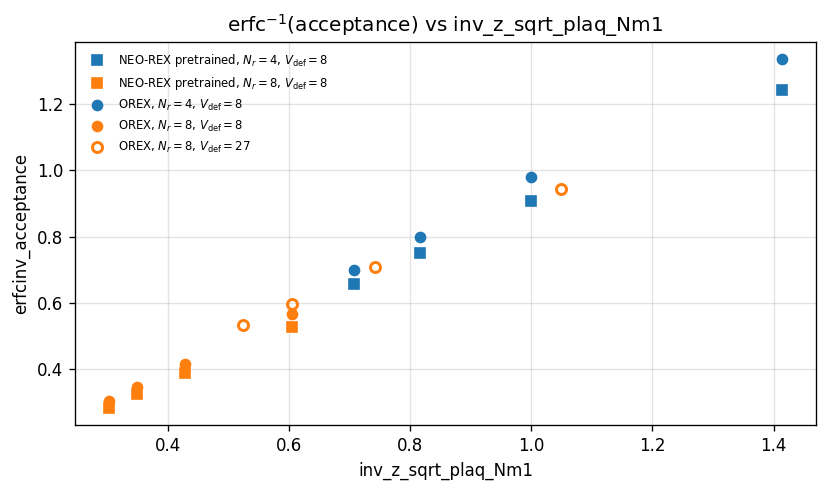

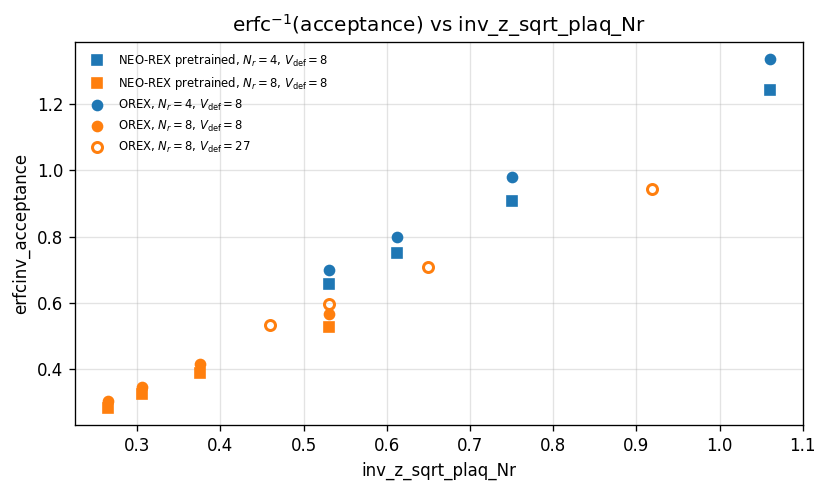

In [8]:

if erfcinv is not None:
    for x_col in ['inv_z_sqrt_vdef_Nm1', 'inv_z_sqrt_vdef_Nr', 'inv_z_sqrt_plaq_Nm1', 'inv_z_sqrt_plaq_Nr']:
        plot_metric_vs(data, x_col, 'erfcinv_acceptance', logx=False, logy=False, title=fr'erfc$^{{-1}}$(acceptance) vs {x_col}', save_name=f'erfcinv_acceptance_vs_{x_col}')
        plt.show()
else:
    print('scipy.special.erfcinv is not available in this environment')


## Custom Rescaling Sandbox

Modifica solo `custom_x(df)` e rilancia le due celle sotto. Nessun fit: i plot mostrano solo i dati nel rescaling scelto.

Variabili gia' disponibili in `df`:

- `nsteps_raw`: valore fisico di `nsteps`, quindi PT standard resta `0`
- `nsteps_plus1`: `nsteps + 1`, utile per includere PT standard nei rescaling positivi
- `nsteps_eff`: alias di `nsteps_raw` in questo notebook
- `nreplicas_f`: numero di repliche come float
- `nr_minus_1`: `N_r - 1`
- `defect_volume`: `d^3`
- `n_defect_plaquettes`: `3 d^2(d+1)`
- `swap_acceptance`, `work_mean`, `work_sem`


In [9]:

def custom_x(df):
    """Return the x variable to test.

    Examples to try:
      df['nsteps_raw'] * df['nr_minus_1']**2 / df['defect_volume']
      df['nsteps_plus1'] * df['nr_minus_1']**2 / df['defect_volume']
      df['nsteps_plus1'] * df['nreplicas_f']**2 / df['defect_volume']
      np.sqrt(df['nsteps_plus1']) * df['nr_minus_1'] / np.sqrt(df['defect_volume'])
      np.sqrt(df['nsteps_plus1']) * df['nr_minus_1'] / np.sqrt(df['n_defect_plaquettes'])
    """
    return df['nsteps_plus1'] * df['nr_minus_1']**2 / df['defect_volume']

custom = data.copy()
custom['x_custom'] = custom_x(custom)
custom[['algorithm', 'defect_size', 'defect_volume', 'n_defect_plaquettes', 'nreplicas', 'nsteps', 'nsteps_raw', 'nsteps_plus1', 'x_custom', 'swap_acceptance', 'work_mean']]


,algorithm,defect_size,defect_volume,n_defect_plaquettes,nreplicas,nsteps,nsteps_raw,nsteps_plus1,x_custom,swap_acceptance,work_mean
0,NEO-REX pretrained,2,8,36.0,4,2,2.0,3.0,3.375000,0.078464,6.952978
1,NEO-REX pretrained,2,8,36.0,4,4,4.0,5.0,5.625000,0.199271,3.530432
2,NEO-REX pretrained,2,8,36.0,4,6,6.0,7.0,7.875000,0.289141,2.367685
3,NEO-REX pretrained,2,8,36.0,4,8,8.0,9.0,10.125000,0.353490,1.789984
4,NEO-REX pretrained,2,8,36.0,8,2,2.0,3.0,18.375000,0.457455,1.172992
5,NEO-REX pretrained,2,8,36.0,8,4,4.0,5.0,30.625000,0.583281,0.619129
6,NEO-REX pretrained,2,8,36.0,8,6,6.0,7.0,42.875000,0.648393,0.428084
7,NEO-REX pretrained,2,8,36.0,8,8,8.0,9.0,55.125000,0.690379,0.322369
8,OREX,2,8,36.0,4,0,0.0,1.0,1.125000,0.010286,15.468660
9,OREX,2,8,36.0,4,2,2.0,3.0,3.375000,0.058750,7.980036


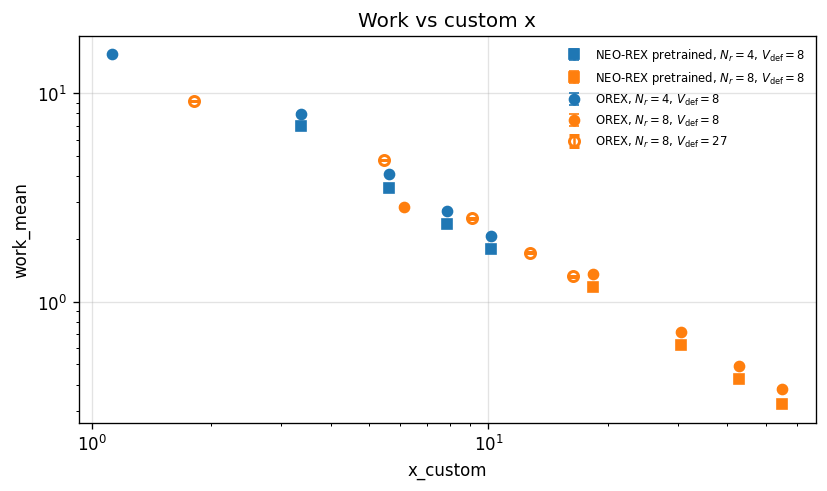

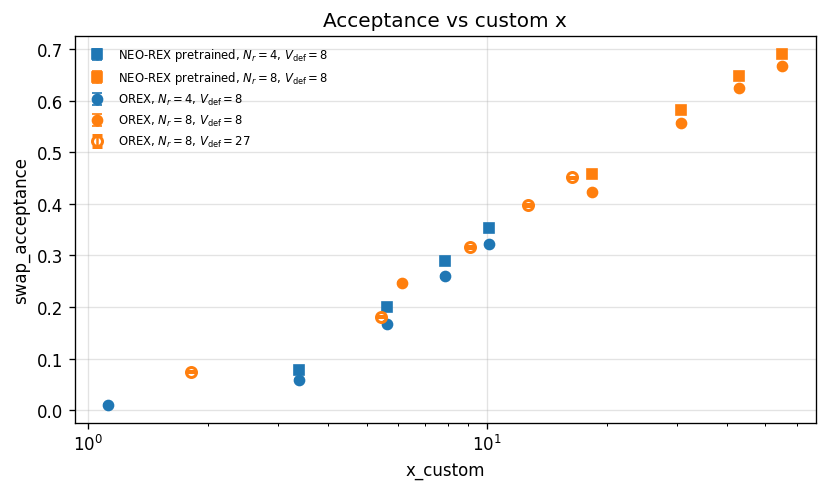

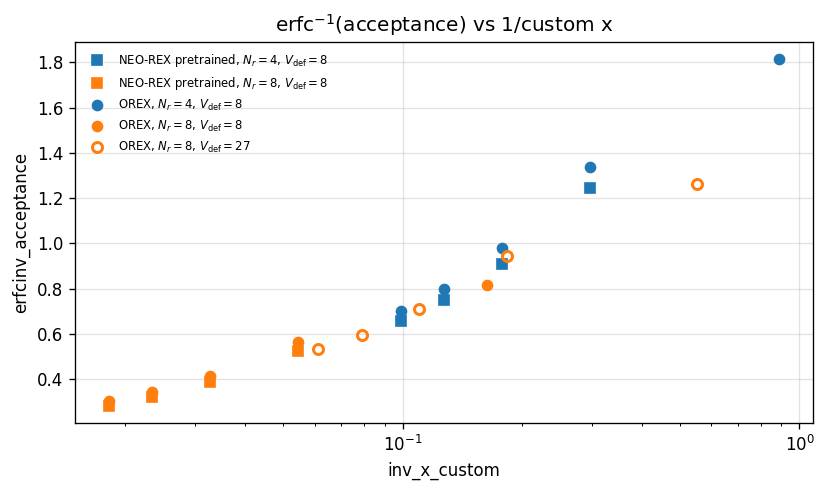

In [10]:

plot_metric_vs(custom, 'x_custom', 'work_mean', yerr_col='work_sem', logx=True, logy=True, title='Work vs custom x', save_name='custom_work_vs_x')
plt.show()

plot_metric_vs(custom, 'x_custom', 'swap_acceptance', yerr_col='swap_acceptance_sem', logx=True, logy=False, title='Acceptance vs custom x', save_name='custom_acceptance_vs_x')
plt.show()

if erfcinv is not None:
    custom['inv_x_custom'] = 1.0 / custom['x_custom']
    plot_metric_vs(custom, 'inv_x_custom', 'erfcinv_acceptance', logx=True, logy=False, title=fr'erfc$^{{-1}}$(acceptance) vs 1/custom x', save_name='custom_erfcinv_acceptance_vs_invx')
    plt.show()
